In [1]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nGPU disponibles:")
print(tf.config.list_physical_devices("GPU"))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0

GPU disponibles:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:

from pathlib import Path

# Carpeta principal de resultados
BASE_DIR = Path("/kaggle/working")

# Subcarpetas del proyecto
carpetas = [
    "modelos",
    "graficas",
    "metricas",
    "particiones",
    "predicciones",
    "gradcam"
]

# Crear las carpetas
for carpeta in carpetas:
    ruta = BASE_DIR / carpeta
    ruta.mkdir(parents=True, exist_ok=True)
    print(f"Carpeta creada: {ruta}")

print("\nEstructura de trabajo preparada.")


Carpeta creada: /kaggle/working/modelos
Carpeta creada: /kaggle/working/graficas
Carpeta creada: /kaggle/working/metricas
Carpeta creada: /kaggle/working/particiones
Carpeta creada: /kaggle/working/predicciones
Carpeta creada: /kaggle/working/gradcam

Estructura de trabajo preparada.


In [3]:

import pandas as pd

# Ruta del dataset
DATA_DIR = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

# Cargar los metadatos
df = pd.read_csv(f"{DATA_DIR}/HAM10000_metadata.csv")

# Comprobar los datos
print("Número de imágenes:", len(df))
print("Número de lesiones diferentes:", df["lesion_id"].nunique())
print("Número de categorías:", df["dx"].nunique())

print("\nColumnas disponibles:")
print(df.columns.tolist())

# Mostrar las primeras cinco filas
display(df.head())



Número de imágenes: 10015
Número de lesiones diferentes: 7470
Número de categorías: 7

Columnas disponibles:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


,Clase,Descripción,Cantidad,Porcentaje (%)
0,nv,Nevos melanocíticos,6705,66.95
1,mel,Melanoma,1113,11.11
2,bkl,Lesiones queratósicas benignas,1099,10.97
3,bcc,Carcinoma basocelular,514,5.13
4,akiec,Queratosis actínica / carcinoma intraepitelial,327,3.27
5,vasc,Lesiones vasculares,142,1.42
6,df,Dermatofibroma,115,1.15


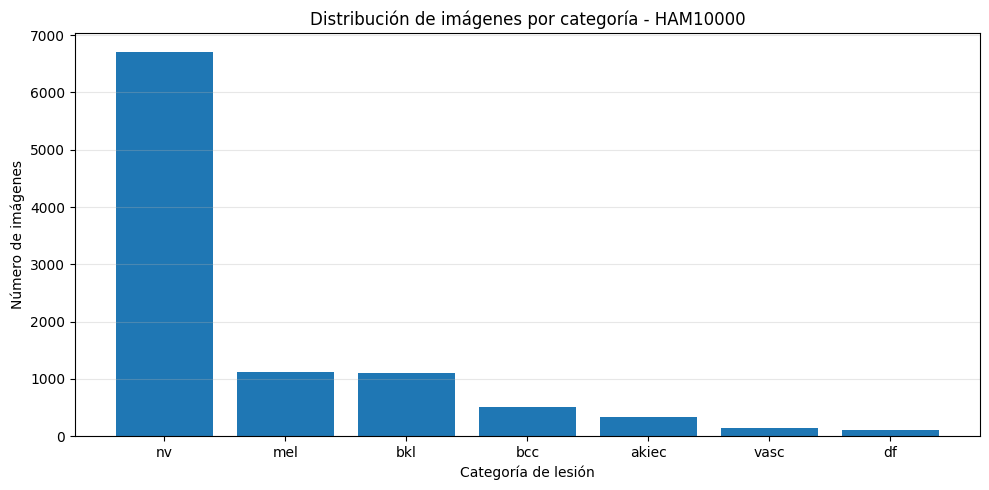

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Nombres de las siete categorías
nombres_clases = {
    "nv": "Nevos melanocíticos",
    "mel": "Melanoma",
    "bkl": "Lesiones queratósicas benignas",
    "bcc": "Carcinoma basocelular",
    "akiec": "Queratosis actínica / carcinoma intraepitelial",
    "vasc": "Lesiones vasculares",
    "df": "Dermatofibroma"
}

# Contar imágenes por categoría
conteos = df["dx"].value_counts()

tabla_clases = pd.DataFrame({
    "Clase": conteos.index,
    "Descripción": [nombres_clases[c] for c in conteos.index],
    "Cantidad": conteos.values,
    "Porcentaje (%)": (conteos.values / len(df) * 100).round(2)
})

display(tabla_clases)

# Visualización de la distribución
plt.figure(figsize=(10, 5))
plt.bar(conteos.index, conteos.values)

plt.title("Distribución de imágenes por categoría - HAM10000")
plt.xlabel("Categoría de lesión")
plt.ylabel("Número de imágenes")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [5]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
)

# Carpetas que contienen las imágenes originales
carpetas = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2"
]

# Crear un diccionario de rutas
rutas_imagenes = {}

for carpeta in carpetas:
    print(f"Carpeta: {carpeta.name}")
    print(f"Existe: {carpeta.exists()}")

    if carpeta.exists():
        imagenes = list(carpeta.glob("*.jpg"))
        print(f"Imágenes encontradas: {len(imagenes)}")

        for imagen in imagenes:
            rutas_imagenes[imagen.stem] = str(imagen)

    print()

# Asociar cada registro con su imagen
df["ruta_imagen"] = df["image_id"].map(rutas_imagenes)

print("Total de imágenes encontradas:", len(rutas_imagenes))
print("Registros sin imagen:", df["ruta_imagen"].isna().sum())
print("Registros con imagen:", df["ruta_imagen"].notna().sum())


Carpeta: HAM10000_images_part_1
Existe: True
Imágenes encontradas: 5000

Carpeta: HAM10000_images_part_2
Existe: True
Imágenes encontradas: 5015

Total de imágenes encontradas: 10015
Registros sin imagen: 0
Registros con imagen: 10015


In [6]:

from sklearn.model_selection import GroupShuffleSplit

# Semilla para reproducibilidad
SEMILLA = 42

# Primera división: 70 % entrenamiento y 30 % temporal
division_1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEMILLA
)

idx_train, idx_temp = next(
    division_1.split(
        df,
        y=df["dx"],
        groups=df["lesion_id"]
    )
)

train_df = df.iloc[idx_train].copy()
temp_df = df.iloc[idx_temp].copy()

# Segunda división: temporal en validación y prueba
division_2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=SEMILLA
)

idx_val, idx_test = next(
    division_2.split(
        temp_df,
        y=temp_df["dx"],
        groups=temp_df["lesion_id"]
    )
)

val_df = temp_df.iloc[idx_val].copy()
test_df = temp_df.iloc[idx_test].copy()

# Verificar los tamaños
print("Entrenamiento:", len(train_df))
print("Validación:", len(val_df))
print("Prueba:", len(test_df))

print("\nPorcentajes:")
print(f"Entrenamiento: {len(train_df)/len(df)*100:.2f}%")
print(f"Validación: {len(val_df)/len(df)*100:.2f}%")
print(f"Prueba: {len(test_df)/len(df)*100:.2f}%")

# Comprobar que no se repiten lesiones
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

print("\nLesiones compartidas:")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

# Distribución de categorías por partición
distribucion = pd.DataFrame({
    "Entrenamiento": train_df["dx"].value_counts(),
    "Validación": val_df["dx"].value_counts(),
    "Prueba": test_df["dx"].value_counts()
}).fillna(0).astype(int)

display(distribucion)


Entrenamiento: 7002
Validación: 1519
Prueba: 1494

Porcentajes:
Entrenamiento: 69.92%
Validación: 15.17%
Prueba: 14.92%

Lesiones compartidas:
Train-Val: 0
Train-Test: 0
Val-Test: 0


,Entrenamiento,Validación,Prueba
dx,,,
akiec,207,57,63
bcc,381,65,68
bkl,741,206,152
df,89,19,7
mel,770,156,187
nv,4718,991,996
vasc,96,25,21


In [7]:

# Verificar si una misma lesión tiene más de una categoría
clases_por_lesion = df.groupby("lesion_id")["dx"].nunique()

lesiones_multiclase = (clases_por_lesion > 1).sum()

print("Lesiones con más de una categoría:", lesiones_multiclase)

# Contar lesiones únicas por categoría
lesiones_por_clase = (
    df.groupby("dx")["lesion_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nLesiones únicas por categoría:")
display(lesiones_por_clase)


Lesiones con más de una categoría: 0

Lesiones únicas por categoría:


dx
nv       5403
bkl       727
mel       614
bcc       327
akiec     228
vasc       98
df         73
Name: lesion_id, dtype: int64

In [8]:

from sklearn.model_selection import train_test_split
import pandas as pd

SEMILLA = 42

# Una fila por lesión, conservando su categoría
lesiones = (
    df[["lesion_id", "dx"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Primera división: 70 % entrenamiento y 30 % temporal
lesiones_train, lesiones_temp = train_test_split(
    lesiones,
    test_size=0.30,
    stratify=lesiones["dx"],
    random_state=SEMILLA
)

# Segunda división: 15 % validación y 15 % prueba
lesiones_val, lesiones_test = train_test_split(
    lesiones_temp,
    test_size=0.50,
    stratify=lesiones_temp["dx"],
    random_state=SEMILLA
)

# Recuperar todas las imágenes de cada lesión
train_df = df[
    df["lesion_id"].isin(lesiones_train["lesion_id"])
].copy()

val_df = df[
    df["lesion_id"].isin(lesiones_val["lesion_id"])
].copy()

test_df = df[
    df["lesion_id"].isin(lesiones_test["lesion_id"])
].copy()

# Mostrar tamaños y porcentajes
print("Tamaños de los conjuntos:\n")

for nombre, datos in [
    ("Entrenamiento", train_df),
    ("Validación", val_df),
    ("Prueba", test_df)
]:
    print(
        f"{nombre}: {len(datos)} imágenes "
        f"({len(datos) / len(df) * 100:.2f} %)"
    )

# Comprobar que ninguna lesión se repite
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

print("\nLesiones compartidas:")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

# Distribución de imágenes por clase
distribucion = pd.DataFrame({
    "Entrenamiento": train_df["dx"].value_counts(),
    "Validación": val_df["dx"].value_counts(),
    "Prueba": test_df["dx"].value_counts()
}).fillna(0).astype(int)

print("\nDistribución por categoría:")
display(distribucion)

# Verificaciones
assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)
assert (distribucion > 0).all().all()

print("\nVerificaciones básicas superadas.")


Tamaños de los conjuntos:

Entrenamiento: 7002 imágenes (69.92 %)
Validación: 1532 imágenes (15.30 %)
Prueba: 1481 imágenes (14.79 %)

Lesiones compartidas:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Distribución por categoría:


,Entrenamiento,Validación,Prueba
dx,,,
akiec,230,51,46
bcc,366,77,71
bkl,774,157,168
df,76,19,20
mel,778,170,165
nv,4679,1034,992
vasc,99,24,19



Verificaciones básicas superadas.


In [9]:

from pathlib import Path
import pandas as pd

# Carpeta donde guardaremos las particiones
CARPETA_PARTICIONES = Path("/kaggle/working/particiones")
CARPETA_PARTICIONES.mkdir(parents=True, exist_ok=True)

# Guardar las tres particiones
train_df.to_csv(CARPETA_PARTICIONES / "train.csv", index=False)
val_df.to_csv(CARPETA_PARTICIONES / "val.csv", index=False)
test_df.to_csv(CARPETA_PARTICIONES / "test.csv", index=False)

# Verificar que se guardaron correctamente
print("PARTICIONES GUARDADAS\n")

for nombre in ["train.csv", "val.csv", "test.csv"]:
    ruta = CARPETA_PARTICIONES / nombre
    datos = pd.read_csv(ruta)
    print(f"{nombre}: {len(datos)} imágenes")

# Comprobar que no hay imágenes repetidas entre conjuntos
assert set(train_df["image_id"]).isdisjoint(val_df["image_id"])
assert set(train_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])

# Comprobar que no hay lesiones compartidas
assert set(train_df["lesion_id"]).isdisjoint(val_df["lesion_id"])
assert set(train_df["lesion_id"]).isdisjoint(test_df["lesion_id"])
assert set(val_df["lesion_id"]).isdisjoint(test_df["lesion_id"])

print("\nVerificación completada: sin imágenes ni lesiones compartidas.")


PARTICIONES GUARDADAS

train.csv: 7002 imágenes
val.csv: 1532 imágenes
test.csv: 1481 imágenes

Verificación completada: sin imágenes ni lesiones compartidas.


In [10]:

import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

# Definir el orden fijo de las siete categorías
CLASES = sorted(train_df["dx"].unique())

# Crear correspondencia entre categorías y números
clase_a_indice = {
    clase: indice
    for indice, clase in enumerate(CLASES)
}

indice_a_clase = {
    indice: clase
    for clase, indice in clase_a_indice.items()
}

# Calcular pesos usando solamente entrenamiento
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array(CLASES),
    y=train_df["dx"].to_numpy()
)

pesos_clase = {
    indice: float(peso)
    for indice, peso in enumerate(pesos)
}

# Mostrar resultados
tabla_pesos = pd.DataFrame({
    "Clase": CLASES,
    "Índice": range(len(CLASES)),
    "Imágenes entrenamiento": [
        (train_df["dx"] == clase).sum()
        for clase in CLASES
    ],
    "Peso": pesos
})

display(tabla_pesos.round(4))


,Clase,Índice,Imágenes entrenamiento,Peso
0,akiec,0,230,4.3491
1,bcc,1,366,2.7330
2,bkl,2,774,1.2924
3,df,3,76,13.1617
4,mel,4,778,1.2857
5,nv,5,4679,0.2138
6,vasc,6,99,10.1039


In [11]:

import tensorflow as tf

# Parámetros del procesamiento
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Convertir categorías a índices numéricos
train_df["label"] = train_df["dx"].map(clase_a_indice)
val_df["label"] = val_df["dx"].map(clase_a_indice)
test_df["label"] = test_df["dx"].map(clase_a_indice)

def cargar_imagen(ruta, etiqueta):
    # Leer archivo de imagen
    imagen = tf.io.read_file(ruta)

    # Decodificar imagen JPG con tres canales RGB
    imagen = tf.image.decode_jpeg(imagen, channels=3)

    # Redimensionar a 224 x 224 píxeles
    imagen = tf.image.resize(imagen, IMG_SIZE)

    # Convertir los valores a float32
    imagen = tf.cast(imagen, tf.float32)

    return imagen, etiqueta

def crear_dataset(datos, entrenamiento=False):
    rutas = datos["ruta_imagen"].astype(str).to_numpy()
    etiquetas = datos["label"].astype("int32").to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (rutas, etiquetas)
    )

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=len(datos),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        cargar_imagen,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

# Crear los tres conjuntos
train_ds = crear_dataset(train_df, entrenamiento=True)
val_ds = crear_dataset(val_df)
test_ds = crear_dataset(test_df)

# Verificar un lote de entrenamiento
for imagenes, etiquetas in train_ds.take(1):
    print("Forma del lote de imágenes:", imagenes.shape)
    print("Forma del lote de etiquetas:", etiquetas.shape)
    print("Tipo de datos:", imagenes.dtype)
    print("Valor mínimo:", tf.reduce_min(imagenes).numpy())
    print("Valor máximo:", tf.reduce_max(imagenes).numpy())


Forma del lote de imágenes: (32, 224, 224, 3)
Forma del lote de etiquetas: (32,)
Tipo de datos: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 255.0


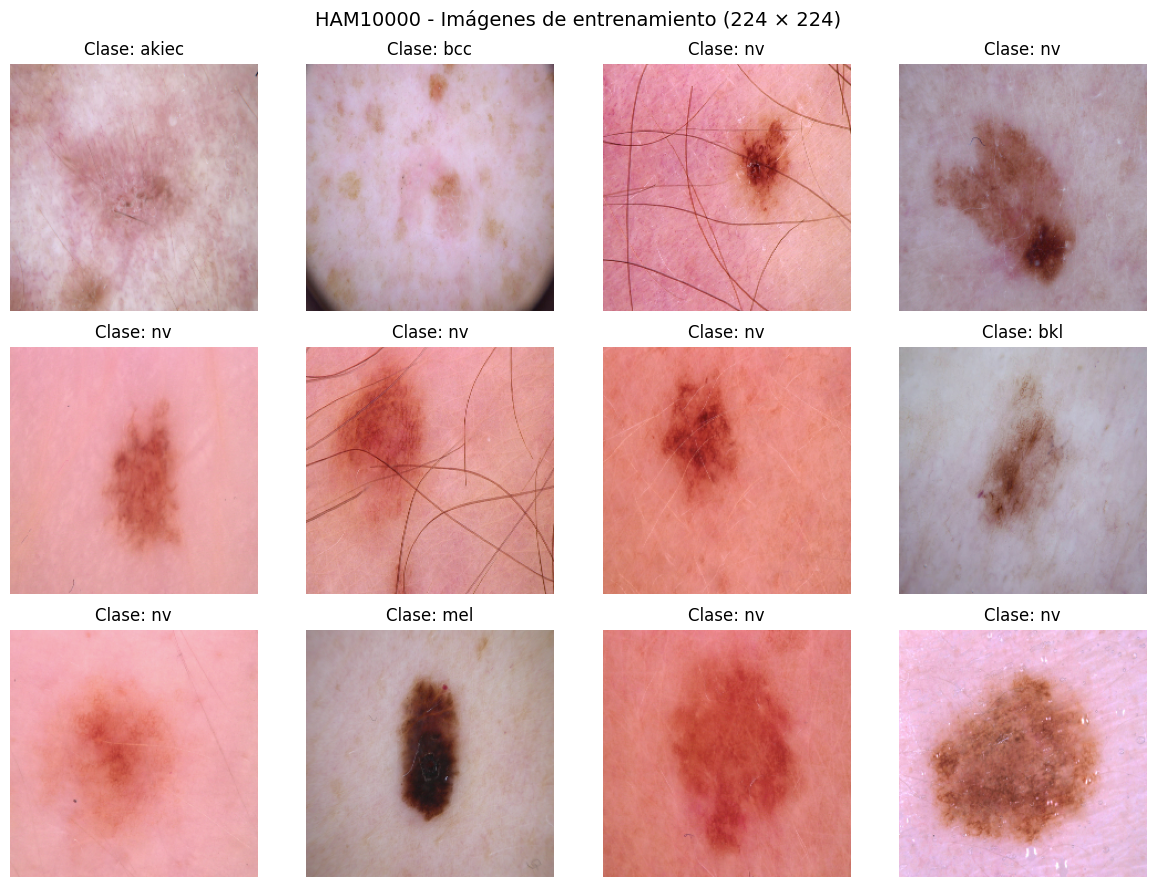

In [12]:

import matplotlib.pyplot as plt
import numpy as np

# Tomar un lote del conjunto de entrenamiento
for imagenes, etiquetas in train_ds.take(1):
    imagenes = imagenes.numpy()
    etiquetas = etiquetas.numpy()

# Mostrar las primeras 12 imágenes
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    imagen = imagenes[i].astype(np.uint8)
    clase = indice_a_clase[int(etiquetas[i])]

    ax.imshow(imagen)
    ax.set_title(f"Clase: {clase}")
    ax.axis("off")

plt.suptitle(
    "HAM10000 - Imágenes de entrenamiento (224 × 224)",
    fontsize=14
)

plt.tight_layout()

# Guardar la figura para el informe y GitHub
plt.savefig(
    "/kaggle/working/graficas/imagenes_preprocesadas.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [13]:

import tensorflow as tf

# Transformaciones que se aplicarán durante entrenamiento
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal_and_vertical",
        seed=42
    ),
    tf.keras.layers.RandomRotation(
        factor=0.10,
        fill_mode="reflect",
        seed=42
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=42
    )
], name="data_augmentation")

print("Data Augmentation configurado correctamente.")


Data Augmentation configurado correctamente.


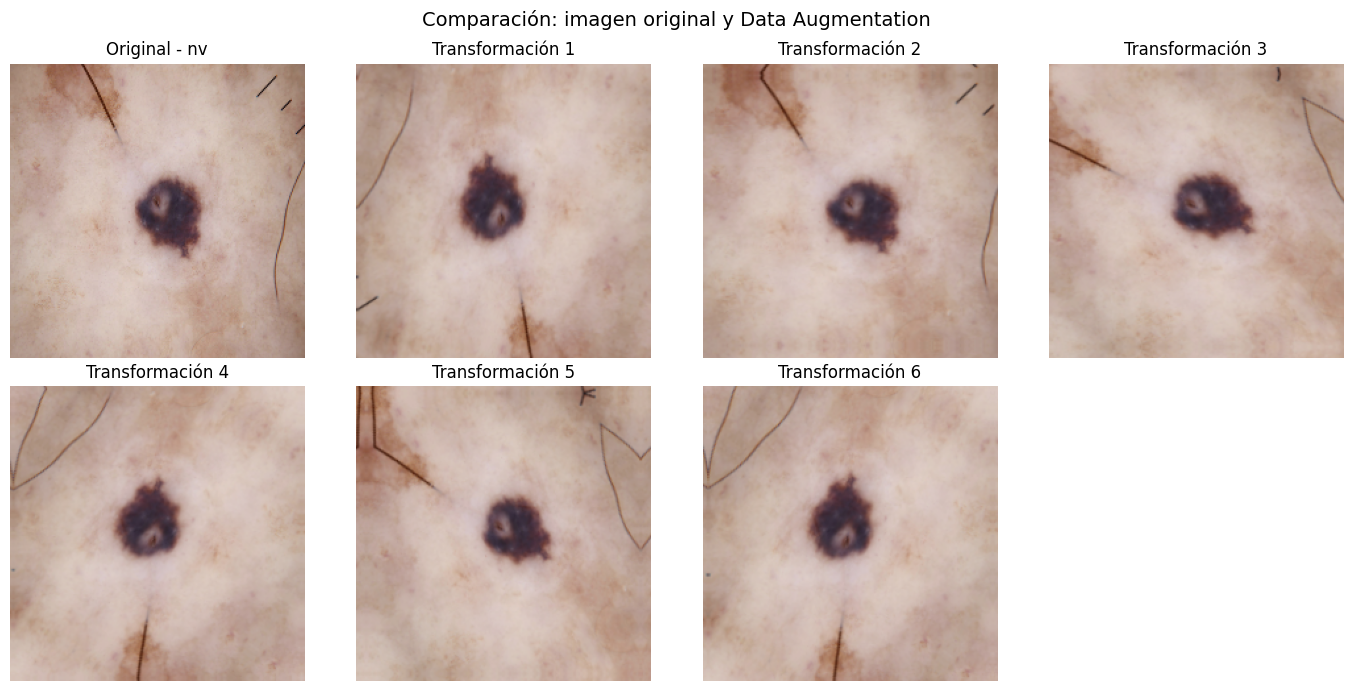

In [14]:

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Tomar un lote del conjunto de entrenamiento
for imagenes, etiquetas in train_ds.take(1):
    imagen_original = imagenes[0]
    etiqueta_original = int(etiquetas[0].numpy())
    break

# Mostrar la imagen original y seis versiones aumentadas
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

axes = axes.flatten()

# Imagen original
axes[0].imshow(
    imagen_original.numpy().astype(np.uint8)
)
axes[0].set_title(
    f"Original - {indice_a_clase[etiqueta_original]}"
)
axes[0].axis("off")

# Seis transformaciones aleatorias
for i in range(1, 7):
    imagen_aumentada = data_augmentation(
        tf.expand_dims(imagen_original, axis=0),
        training=True
    )

    imagen_aumentada = tf.clip_by_value(
        imagen_aumentada[0], 0, 255
    )

    axes[i].imshow(
        imagen_aumentada.numpy().astype(np.uint8)
    )
    axes[i].set_title(f"Transformación {i}")
    axes[i].axis("off")

# Ocultar la última posición
axes[7].axis("off")

plt.suptitle(
    "Comparación: imagen original y Data Augmentation",
    fontsize=14
)

plt.tight_layout()

# Guardar figura
plt.savefig(
    "/kaggle/working/graficas/data_augmentation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [15]:

import tensorflow as tf

# Cargar EfficientNetB0 con pesos preentrenados en ImageNet.
# include_top=False elimina el clasificador original de ImageNet.
# La nueva cabeza clasificadora se agregará posteriormente.

try:
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3)
    )

    # Congelar la base para la primera fase de entrenamiento
    base_model.trainable = False

    print("EfficientNetB0 cargada correctamente.")
    print("Base congelada:", not base_model.trainable)
    print("Capas de la base:", len(base_model.layers))

except Exception as error:
    base_model = None
    print("No se pudieron cargar los pesos de ImageNet.")
    print("Detalle:", str(error)[:800])


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 cargada correctamente.
Base congelada: True
Capas de la base: 238


In [16]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# Número de categorías
NUM_CLASES = len(CLASES)

# Verificar que la base preentrenada está disponible
assert base_model is not None, "Primero carga EfficientNetB0."
assert NUM_CLASES == 7

# Mantener congelada la base preentrenada
base_model.trainable = False

# 1. Entrada de imágenes RGB
entradas = layers.Input(
    shape=(224, 224, 3),
    name="imagen_entrada"
)

# 2. Aumento de datos
x = data_augmentation(entradas)

# 3. Extracción de características con EfficientNetB0
# training=False mantiene BatchNormalization en modo inferencia
x = base_model(x, training=False)

# 4. Resumir los mapas de características
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

# 5. Regularización
x = layers.Dropout(
    rate=0.3,
    name="dropout_clasificador"
)(x)

# 6. Clasificación en siete categorías
salidas = layers.Dense(
    NUM_CLASES,
    activation="softmax",
    name="predicciones"
)(x)

# Construir el modelo completo
modelo_a = Model(
    inputs=entradas,
    outputs=salidas,
    name="EfficientNetB0_HAM10000"
)

# Mostrar resumen de la arquitectura
modelo_a.summary()


Model: "EfficientNetB0_HAM10000"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_entrada (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_clasificador (Dropout)  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicciones (Dense)            │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [17]:

import tensorflow as tf

# Configuración de la primera fase:
# entrenar la cabeza clasificadora con EfficientNetB0 congelada.

TASA_APRENDIZAJE_FASE1 = 1e-3

modelo_a.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TASA_APRENDIZAJE_FASE1
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Modelo compilado correctamente.")
print("Optimizador: Adam")
print("Learning rate:", TASA_APRENDIZAJE_FASE1)
print("Función de pérdida: SparseCategoricalCrossentropy")
print("Métrica: Accuracy")


Modelo compilado correctamente.
Optimizador: Adam
Learning rate: 0.001
Función de pérdida: SparseCategoricalCrossentropy
Métrica: Accuracy


In [18]:

import os
import tensorflow as tf

# Carpeta para guardar los modelos entrenados
os.makedirs("/kaggle/working/modelos", exist_ok=True)

# Guardar el modelo con menor pérdida de validación
checkpoint_fase1 = tf.keras.callbacks.ModelCheckpoint(
    filepath="/kaggle/working/modelos/modelo_a_fase1_mejor.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Detener el entrenamiento si no mejora durante 5 épocas
early_stopping_fase1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reducir la tasa de aprendizaje si la validación se estanca
reduce_lr_fase1 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Agrupar los mecanismos
callbacks_fase1 = [
    checkpoint_fase1,
    early_stopping_fase1,
    reduce_lr_fase1
]

print("Callbacks configurados correctamente.")
print("Modelo:", modelo_a.name)
print("Número de callbacks:", len(callbacks_fase1))


Callbacks configurados correctamente.
Modelo: EfficientNetB0_HAM10000
Número de callbacks: 3


In [19]:

# FASE 1: entrenamiento de la cabeza clasificadora
# EfficientNetB0 permanece congelada.

EPOCAS_FASE1 = 20

historial_fase1 = modelo_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_FASE1,
    class_weight=pesos_clase,
    callbacks=callbacks_fase1,
    verbose=1
)

print("Entrenamiento de la fase 1 finalizado.")


Epoch 1/20


E0000 00:00:1794438054.769840      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_HAM10000_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.3412 - loss: 1.7935
Epoch 1: val_loss improved from None to 1.35431, saving model to /kaggle/working/modelos/modelo_a_fase1_mejor.keras

Epoch 1: finished saving model to /kaggle/working/modelos/modelo_a_fase1_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 118s 489ms/step - accuracy: 0.4033 - loss: 1.6686 - val_accuracy: 0.5157 - val_loss: 1.3543 - learning_rate: 0.0010
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5057 - loss: 1.3690
Epoch 2: val_loss improved from 1.35431 to 1.19000, saving model to /kaggle/working/modelos/modelo_a_fase1_mejor.keras

Epoch 2: finished saving model to /kaggle/working/modelos/modelo_a_fase1_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 94ms/step - accuracy: 0.5300 - loss: 1.3322 - val_accuracy: 0.5607 - val_loss: 1.1900 - learning_rate: 0.0010
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5478 - loss: 1.2095
Epoch 3: val_loss improved from 1.19000 to 0.98203, sa

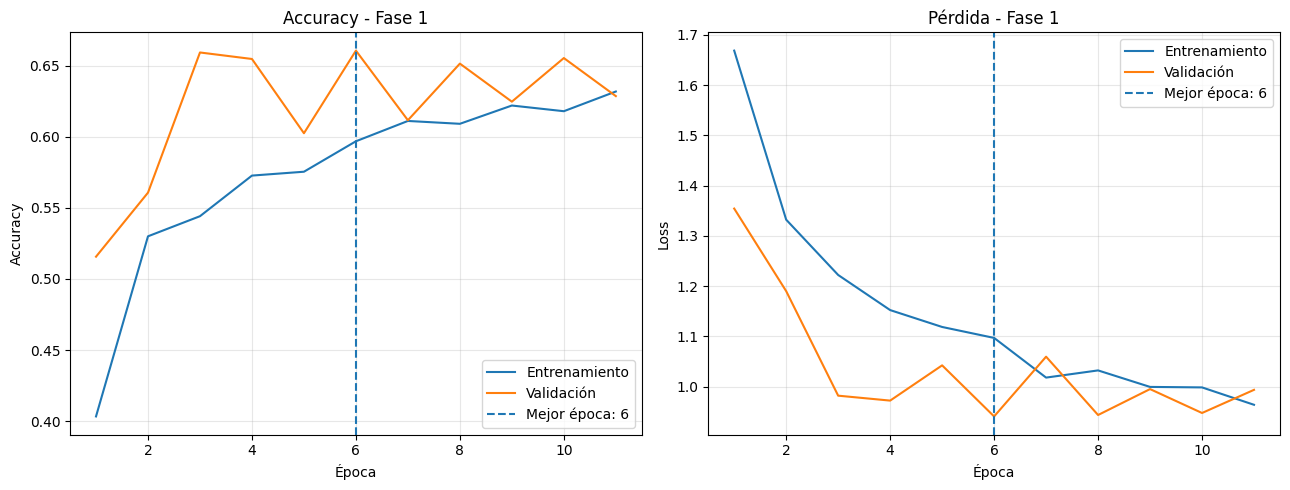

Historial guardado: /kaggle/working/metricas/historial_modelo_a_fase1.csv
Gráfica guardada: /kaggle/working/graficas/entrenamiento_modelo_a_fase1.png
Mejor época: 6
Mejor val_accuracy: 0.6606
Mejor val_loss: 0.9407


In [20]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Crear carpetas para los resultados
os.makedirs("/kaggle/working/graficas", exist_ok=True)
os.makedirs("/kaggle/working/metricas", exist_ok=True)

# Convertir el historial de entrenamiento a DataFrame
df_historial_fase1 = pd.DataFrame(historial_fase1.history)

# Agregar número de época
df_historial_fase1.insert(
    0,
    "epoca",
    range(1, len(df_historial_fase1) + 1)
)

# Guardar historial en CSV
ruta_historial = (
    "/kaggle/working/metricas/historial_modelo_a_fase1.csv"
)

df_historial_fase1.to_csv(
    ruta_historial,
    index=False
)

# Identificar la mejor época según val_loss
mejor_indice = df_historial_fase1["val_loss"].idxmin()
mejor_epoca = int(df_historial_fase1.loc[mejor_indice, "epoca"])

# Graficar evolución del entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfica de accuracy
axes[0].plot(
    df_historial_fase1["epoca"],
    df_historial_fase1["accuracy"],
    label="Entrenamiento"
)

axes[0].plot(
    df_historial_fase1["epoca"],
    df_historial_fase1["val_accuracy"],
    label="Validación"
)

axes[0].axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)

axes[0].set_title("Accuracy - Fase 1")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfica de pérdida
axes[1].plot(
    df_historial_fase1["epoca"],
    df_historial_fase1["loss"],
    label="Entrenamiento"
)

axes[1].plot(
    df_historial_fase1["epoca"],
    df_historial_fase1["val_loss"],
    label="Validación"
)

axes[1].axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)

axes[1].set_title("Pérdida - Fase 1")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Guardar figura
ruta_grafica = (
    "/kaggle/working/graficas/entrenamiento_modelo_a_fase1.png"
)

plt.savefig(ruta_grafica, dpi=200, bbox_inches="tight")
plt.show()

print("Historial guardado:", ruta_historial)
print("Gráfica guardada:", ruta_grafica)
print("Mejor época:", mejor_epoca)
print(
    "Mejor val_accuracy:",
    round(float(df_historial_fase1.loc[mejor_indice, "val_accuracy"]), 4)
)
print(
    "Mejor val_loss:",
    round(float(df_historial_fase1.loc[mejor_indice, "val_loss"]), 4)
)


In [21]:

import tensorflow as tf

# FASE 2: recompilación para fine-tuning
# Se conservan los pesos aprendidos en la fase 1.

TASA_APRENDIZAJE_FASE2 = 1e-5

modelo_a.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TASA_APRENDIZAJE_FASE2
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Verificar la nueva cantidad de parámetros entrenables
print("Modelo recompilado para fine-tuning.")
print("Learning rate:", TASA_APRENDIZAJE_FASE2)

print(
    "Parámetros entrenables:",
    sum(
        tf.keras.backend.count_params(p)
        for p in modelo_a.trainable_weights
    )
)

print(
    "Parámetros no entrenables:",
    sum(
        tf.keras.backend.count_params(p)
        for p in modelo_a.non_trainable_weights
    )
)


Modelo recompilado para fine-tuning.
Learning rate: 1e-05
Parámetros entrenables: 8967
Parámetros no entrenables: 4049571.0


In [22]:

import os
import tensorflow as tf

# Crear carpeta de modelos si no existe
os.makedirs("/kaggle/working/modelos", exist_ok=True)

# Guardar el mejor modelo de la fase 2
checkpoint_fase2 = tf.keras.callbacks.ModelCheckpoint(
    filepath="/kaggle/working/modelos/modelo_a_fase2_mejor.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Detener si la pérdida de validación deja de mejorar
early_stopping_fase2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reducir el learning rate cuando se estanque la validación
reduce_lr_fase2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks_fase2 = [
    checkpoint_fase2,
    early_stopping_fase2,
    reduce_lr_fase2
]

print("Callbacks de fine-tuning configurados correctamente.")
print("Cantidad:", len(callbacks_fase2))
print("Archivo:", checkpoint_fase2.filepath)


Callbacks de fine-tuning configurados correctamente.
Cantidad: 3
Archivo: /kaggle/working/modelos/modelo_a_fase2_mejor.keras


In [23]:

# FASE 2: entrenamiento mediante fine-tuning
# Se parte de los mejores pesos restaurados de la fase 1.

EPOCAS_FASE2 = 20

historial_fase2 = modelo_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_FASE2,
    class_weight=pesos_clase,
    callbacks=callbacks_fase2,
    verbose=1
)

print("Fine-tuning finalizado.")


Epoch 1/20


E0000 00:00:1794438379.674940      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_HAM10000_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6175 - loss: 1.0035
Epoch 1: val_loss improved from None to 0.95111, saving model to /kaggle/working/modelos/modelo_a_fase2_mejor.keras

Epoch 1: finished saving model to /kaggle/working/modelos/modelo_a_fase2_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - accuracy: 0.6205 - loss: 1.0340 - val_accuracy: 0.6508 - val_loss: 0.9511 - learning_rate: 1.0000e-05
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6300 - loss: 0.9745
Epoch 2: val_loss did not improve from 0.95111
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.6237 - loss: 1.0219 - val_accuracy: 0.6475 - val_loss: 0.9616 - learning_rate: 1.0000e-05
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6131 - loss: 1.0030
Epoch 3: val_loss did not improve from 0.95111

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 92ms/step - accuracy: 0.6210 - loss: 1.0179 - val

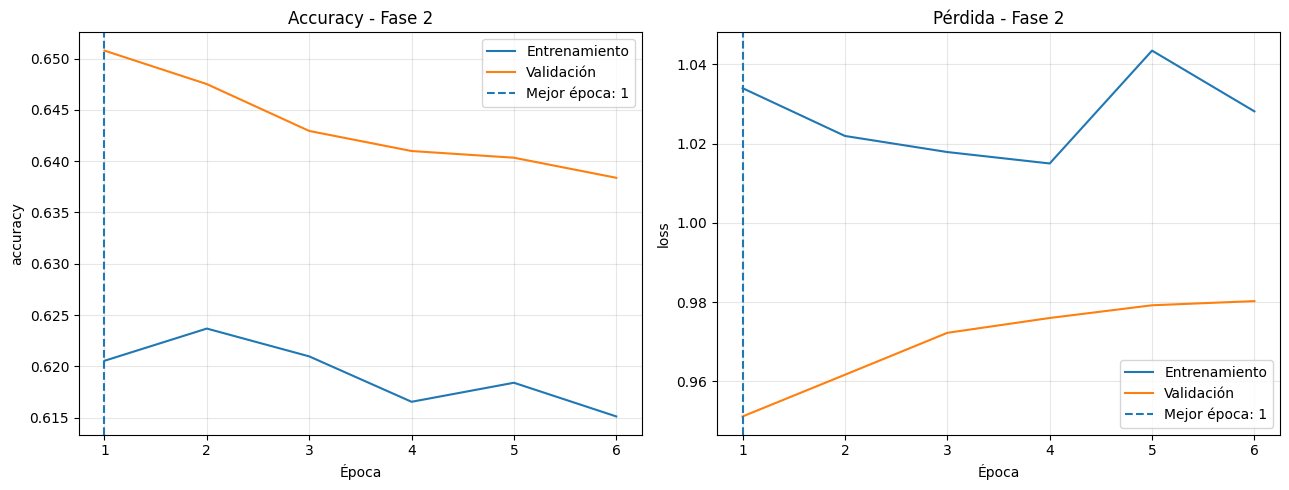

Historial guardado: /kaggle/working/metricas/historial_modelo_a_fase2.csv
Gráfica guardada: /kaggle/working/graficas/entrenamiento_modelo_a_fase2.png
Mejor época: 1
Mejor val_accuracy: 0.6507833003997803
Mejor val_loss: 0.9511134624481201


In [24]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Guardar el historial de la fase 2
df_historial_fase2 = pd.DataFrame(historial_fase2.history)

df_historial_fase2.insert(
    0,
    "epoca",
    range(1, len(df_historial_fase2) + 1)
)

ruta_historial_fase2 = (
    "/kaggle/working/metricas/historial_modelo_a_fase2.csv"
)

df_historial_fase2.to_csv(
    ruta_historial_fase2,
    index=False
)

# Identificar la mejor época según la pérdida de validación
mejor_indice_fase2 = df_historial_fase2["val_loss"].idxmin()
mejor_epoca_fase2 = int(
    df_historial_fase2.loc[mejor_indice_fase2, "epoca"]
)

# Graficar accuracy y pérdida
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for columna, titulo, eje in [
    ("accuracy", "Accuracy - Fase 2", axes[0]),
    ("loss", "Pérdida - Fase 2", axes[1])
]:
    eje.plot(
        df_historial_fase2["epoca"],
        df_historial_fase2[columna],
        label="Entrenamiento"
    )

    eje.plot(
        df_historial_fase2["epoca"],
        df_historial_fase2["val_" + columna],
        label="Validación"
    )

    eje.axvline(
        mejor_epoca_fase2,
        linestyle="--",
        label=f"Mejor época: {mejor_epoca_fase2}"
    )

    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_ylabel(columna)
    eje.legend()
    eje.grid(alpha=0.3)

plt.tight_layout()

ruta_grafica_fase2 = (
    "/kaggle/working/graficas/entrenamiento_modelo_a_fase2.png"
)

plt.savefig(
    ruta_grafica_fase2,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Historial guardado:", ruta_historial_fase2)
print("Gráfica guardada:", ruta_grafica_fase2)
print("Mejor época:", mejor_epoca_fase2)
print(
    "Mejor val_accuracy:",
    df_historial_fase2.loc[mejor_indice_fase2, "val_accuracy"]
)
print(
    "Mejor val_loss:",
    df_historial_fase2.loc[mejor_indice_fase2, "val_loss"]
)


In [25]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Rutas de los mejores modelos de cada fase
RUTA_FASE1 = "/kaggle/working/modelos/modelo_a_fase1_mejor.keras"
RUTA_FASE2 = "/kaggle/working/modelos/modelo_a_fase2_mejor.keras"

# Verificar que ambos modelos estén guardados
assert os.path.exists(RUTA_FASE1), "No se encontró el modelo de fase 1."
assert os.path.exists(RUTA_FASE2), "No se encontró el modelo de fase 2."

# Cargar los modelos sin recompilar el optimizador
modelo_fase1 = tf.keras.models.load_model(
    RUTA_FASE1,
    compile=False
)

modelo_fase2 = tf.keras.models.load_model(
    RUTA_FASE2,
    compile=False
)

# Las etiquetas siguen el orden original de val_df.
# val_ds no fue mezclado, a diferencia de train_ds.
y_real = val_df["label"].to_numpy()

assert len(y_real) == 1532
assert len(CLASES) == 7

def evaluar_validacion(modelo, nombre):
    # Probabilidades para las siete categorías
    probabilidades = modelo.predict(
        val_ds,
        verbose=1
    )

    # Categoría con mayor probabilidad
    y_pred = np.argmax(probabilidades, axis=1)

    assert len(y_pred) == len(y_real)

    # Métricas globales
    metricas = {
        "modelo": nombre,
        "accuracy": accuracy_score(y_real, y_pred),
        "macro_f1": f1_score(
            y_real, y_pred,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_pred
        )
    }

    # Métricas individuales de cada categoría
    reporte = classification_report(
        y_real,
        y_pred,
        labels=list(range(len(CLASES))),
        target_names=CLASES,
        output_dict=True,
        zero_division=0
    )

    # Matriz de confusión
    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=list(range(len(CLASES)))
    )

    return metricas, pd.DataFrame(reporte).T, matriz


# Evaluar ambos modelos sobre el mismo conjunto
metricas_fase1, reporte_fase1, matriz_fase1 = evaluar_validacion(
    modelo_fase1, "Fase 1"
)

metricas_fase2, reporte_fase2, matriz_fase2 = evaluar_validacion(
    modelo_fase2, "Fase 2"
)

# Tabla comparativa
comparacion = pd.DataFrame([
    metricas_fase1,
    metricas_fase2
])

print("\nCOMPARACIÓN GLOBAL EN VALIDACIÓN")
print(comparacion.round(4).to_string(index=False))

print("\nRECALL POR CATEGORÍA")
comparacion_recall = pd.DataFrame({
    "clase": CLASES,
    "recall_fase1": [
        reporte_fase1.loc[c, "recall"] for c in CLASES
    ],
    "recall_fase2": [
        reporte_fase2.loc[c, "recall"] for c in CLASES
    ]
})

print(comparacion_recall.round(4).to_string(index=False))

# Guardar resultados
os.makedirs("/kaggle/working/metricas", exist_ok=True)

comparacion.to_csv(
    "/kaggle/working/metricas/comparacion_fases_validacion.csv",
    index=False
)

comparacion_recall.to_csv(
    "/kaggle/working/metricas/recall_por_clase_validacion.csv",
    index=False
)

reporte_fase1.to_csv(
    "/kaggle/working/metricas/reporte_fase1_validacion.csv"
)

reporte_fase2.to_csv(
    "/kaggle/working/metricas/reporte_fase2_validacion.csv"
)

print("\nResultados guardados correctamente.")


48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step

COMPARACIÓN GLOBAL EN VALIDACIÓN
modelo  accuracy  macro_f1  balanced_accuracy
Fase 1    0.6606    0.4511             0.5738
Fase 2    0.6508    0.4483             0.5660

RECALL POR CATEGORÍA
clase  recall_fase1  recall_fase2
akiec        0.5882        0.5098
  bcc        0.2857        0.3117
  bkl        0.5287        0.5350
   df        0.5263        0.5263
  mel        0.4235        0.4294
   nv        0.7476        0.7331
 vasc        0.9167        0.9167

Resultados guardados correctamente.


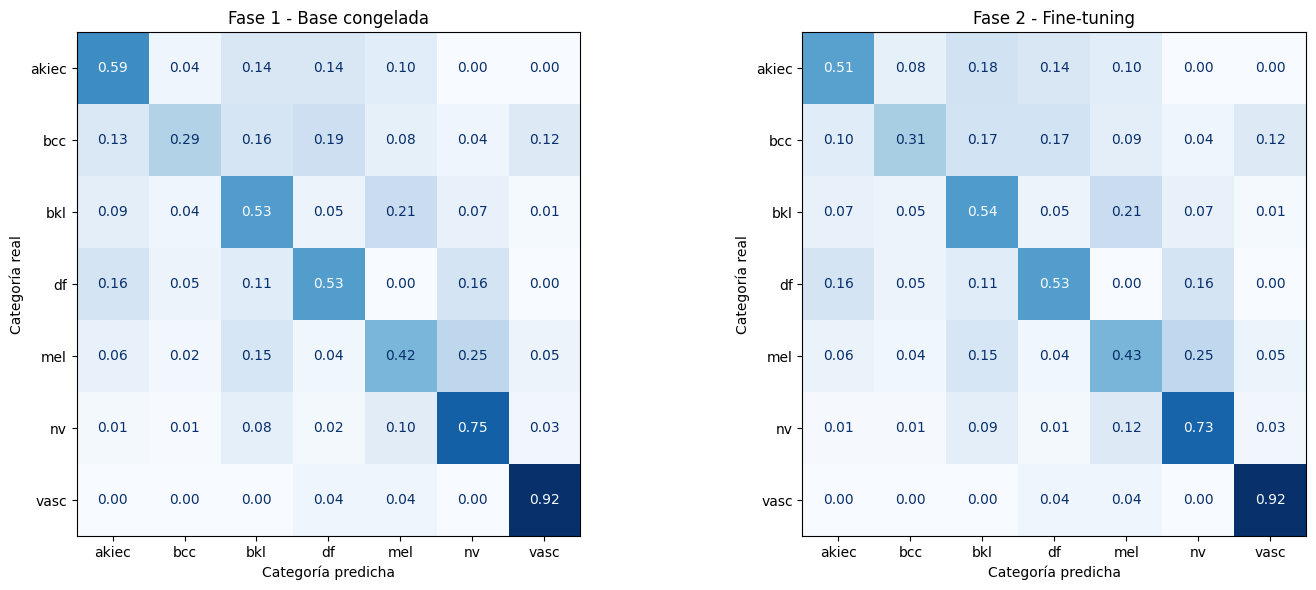

Matrices guardadas en: /kaggle/working/graficas/matrices_confusion_validacion_fases1_2.png


In [26]:

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matrices de confusión calculadas previamente
matrices = [
    ("Fase 1 - Base congelada", matriz_fase1),
    ("Fase 2 - Fine-tuning", matriz_fase2)
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (titulo, matriz) in zip(axes, matrices):

    # Normalizar por el total de imágenes de cada categoría real
    totales = matriz.sum(axis=1, keepdims=True)

    matriz_normalizada = np.divide(
        matriz,
        totales,
        out=np.zeros_like(matriz, dtype=float),
        where=totales != 0
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=matriz_normalizada,
        display_labels=CLASES
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )

    ax.set_title(titulo)
    ax.set_xlabel("Categoría predicha")
    ax.set_ylabel("Categoría real")

plt.tight_layout()

ruta_matrices = (
    "/kaggle/working/graficas/"
    "matrices_confusion_validacion_fases1_2.png"
)

plt.savefig(
    ruta_matrices,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Matrices guardadas en:", ruta_matrices)


In [27]:

import pandas as pd

# Comparar precisión y F1 de las siete categorías
comparacion_detallada = pd.DataFrame({
    "clase": CLASES,

    "precision_fase1": [
        reporte_fase1.loc[c, "precision"]
        for c in CLASES
    ],

    "precision_fase2": [
        reporte_fase2.loc[c, "precision"]
        for c in CLASES
    ],

    "f1_fase1": [
        reporte_fase1.loc[c, "f1-score"]
        for c in CLASES
    ],

    "f1_fase2": [
        reporte_fase2.loc[c, "f1-score"]
        for c in CLASES
    ]
})

# Mostrar tabla
print("PRECISIÓN Y F1 POR CATEGORÍA")
print(
    comparacion_detallada.round(4).to_string(index=False)
)

# Guardar resultados para documentación
comparacion_detallada.to_csv(
    "/kaggle/working/metricas/"
    "comparacion_precision_f1_por_clase.csv",
    index=False
)

print("\nComparación guardada correctamente.")


PRECISIÓN Y F1 POR CATEGORÍA
clase  precision_fase1  precision_fase2  f1_fase1  f1_fase2
akiec           0.3614           0.3881    0.4478    0.4407
  bcc           0.5366           0.4706    0.3729    0.3750
  bkl           0.3860           0.3717    0.4462    0.4386
   df           0.1587           0.1667    0.2439    0.2532
  mel           0.3214           0.3067    0.3655    0.3578
   nv           0.9280           0.9278    0.8281    0.8190
 vasc           0.3014           0.3014    0.4536    0.4536

Comparación guardada correctamente.


In [28]:

import os
import numpy as np
import pandas as pd

# Experimento A2: pesos de clase suavizados
# Se calculan exclusivamente a partir de los pesos
# originales obtenidos con el conjunto de entrenamiento.

pesos_clase_a2 = {
    indice: float(np.sqrt(peso))
    for indice, peso in pesos_clase.items()
}

# Construir tabla comparativa
tabla_pesos_a2 = pd.DataFrame({
    "clase": CLASES,
    "indice": list(range(len(CLASES))),
    "peso_original": [
        pesos_clase[i] for i in range(len(CLASES))
    ],
    "peso_suavizado": [
        pesos_clase_a2[i] for i in range(len(CLASES))
    ]
})

print("COMPARACIÓN DE PESOS DE CLASE")
print(tabla_pesos_a2.round(4).to_string(index=False))

# Guardar tabla para GitHub
os.makedirs("/kaggle/working/metricas", exist_ok=True)

ruta_pesos_a2 = (
    "/kaggle/working/metricas/"
    "comparacion_pesos_clase_a2.csv"
)

tabla_pesos_a2.to_csv(
    ruta_pesos_a2,
    index=False
)

print("\nPesos suavizados guardados en:", ruta_pesos_a2)


COMPARACIÓN DE PESOS DE CLASE
clase  indice  peso_original  peso_suavizado
akiec       0         4.3491          2.0854
  bcc       1         2.7330          1.6532
  bkl       2         1.2924          1.1368
   df       3        13.1617          3.6279
  mel       4         1.2857          1.1339
   nv       5         0.2138          0.4624
 vasc       6        10.1039          3.1787

Pesos suavizados guardados en: /kaggle/working/metricas/comparacion_pesos_clase_a2.csv


In [29]:

import tensorflow as tf

# MODELO A2
# Misma arquitectura que el Modelo A.
# El cambio experimental será el uso de pesos suavizados.

# Fijar semilla para favorecer la reproducibilidad
tf.keras.utils.set_random_seed(42)

# Crear una nueva instancia de EfficientNetB0
base_model_a2 = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Fase inicial: mantener la base congelada
base_model_a2.trainable = False

# Crear una instancia independiente de Data Augmentation
data_augmentation_a2 = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal_and_vertical",
        seed=42
    ),
    tf.keras.layers.RandomRotation(
        factor=0.10,
        fill_mode="reflect",
        seed=42
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=42
    )
], name="data_augmentation_a2")

# Entrada del modelo
entradas_a2 = tf.keras.Input(
    shape=(224, 224, 3),
    name="imagen_entrada_a2"
)

# Transformaciones aleatorias durante entrenamiento
x = data_augmentation_a2(entradas_a2)

# Extracción de características
# training=False conserva BatchNormalization en modo inferencia
x = base_model_a2(x, training=False)

# Convertir mapas de características en un vector
x = tf.keras.layers.GlobalAveragePooling2D(
    name="global_average_pooling_a2"
)(x)

# Regularización
x = tf.keras.layers.Dropout(
    0.3,
    name="dropout_clasificador_a2"
)(x)

# Clasificación multiclase
salidas_a2 = tf.keras.layers.Dense(
    len(CLASES),
    activation="softmax",
    name="predicciones_a2"
)(x)

# Construir modelo independiente
modelo_a2 = tf.keras.Model(
    inputs=entradas_a2,
    outputs=salidas_a2,
    name="EfficientNetB0_HAM10000_A2"
)

# Verificar arquitectura
modelo_a2.summary()

print("\nModelo A2 construido correctamente.")
print("Base congelada:", not base_model_a2.trainable)
print("Categorías:", CLASES)


Model: "EfficientNetB0_HAM10000_A2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_entrada_a2 (InputLayer)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_a2            │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling_a2       │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_clasificador_a2         │ (None, 1280)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicciones_a2 (Dense)         │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Modelo A2 construido correctamente.
Base congelada: True
Categorías: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [30]:

import os
import tensorflow as tf

# MODELO A2 - FASE 1
# Misma configuración del Modelo A.
# Los pesos suavizados se utilizarán al llamar a fit().

modelo_a2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Carpeta independiente para los modelos A2
os.makedirs("/kaggle/working/modelos/a2", exist_ok=True)

# Guardar el mejor modelo de la fase 1
checkpoint_a2_fase1 = tf.keras.callbacks.ModelCheckpoint(
    filepath="/kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Detención temprana
early_stopping_a2_fase1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reducción automática de learning rate
reduce_lr_a2_fase1 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_a2_fase1 = [
    checkpoint_a2_fase1,
    early_stopping_a2_fase1,
    reduce_lr_a2_fase1
]

print("Modelo A2 compilado correctamente.")
print("Base congelada:", not base_model_a2.trainable)
print("Learning rate inicial: 0.001")
print("Callbacks configurados:", len(callbacks_a2_fase1))
print("Ruta del checkpoint:", checkpoint_a2_fase1.filepath)


Modelo A2 compilado correctamente.
Base congelada: True
Learning rate inicial: 0.001
Callbacks configurados: 3
Ruta del checkpoint: /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras


In [31]:

# MODELO A2 - FASE 1
# Entrenamiento con EfficientNetB0 congelada
# y pesos de clase suavizados.

EPOCAS_A2_FASE1 = 20

historial_a2_fase1 = modelo_a2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_A2_FASE1,
    class_weight=pesos_clase_a2,
    callbacks=callbacks_a2_fase1,
    verbose=1
)

print("\nEntrenamiento A2 - Fase 1 finalizado.")


Epoch 1/20


E0000 00:00:1794438535.896570      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_HAM10000_A2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6167 - loss: 1.2035
Epoch 1: val_loss improved from None to 0.86903, saving model to /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras

Epoch 1: finished saving model to /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 32s 105ms/step - accuracy: 0.6500 - loss: 1.1379 - val_accuracy: 0.7134 - val_loss: 0.8690 - learning_rate: 0.0010
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6961 - loss: 0.9843
Epoch 2: val_loss improved from 0.86903 to 0.83717, saving model to /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras

Epoch 2: finished saving model to /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 95ms/step - accuracy: 0.6985 - loss: 0.9485 - val_accuracy: 0.7095 - val_loss: 0.8372 - learning_rate: 0.0010
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6978 - loss: 0.8999
Epoch 3: val_loss improved from 0.83717 

In [32]:

import os
import pandas as pd
import tensorflow as tf

# Cargar el mejor modelo A2 de la fase 1
ruta_a2_fase1 = (
    "/kaggle/working/modelos/a2/"
    "modelo_a2_fase1_mejor.keras"
)

modelo_a2_fase1 = tf.keras.models.load_model(
    ruta_a2_fase1,
    compile=False
)

# Utilizar la misma función de evaluación anterior
metricas_a2_fase1, reporte_a2_fase1, matriz_a2_fase1 = (
    evaluar_validacion(
        modelo_a2_fase1,
        "A2 - Fase 1"
    )
)

# Comparar los tres modelos evaluados hasta ahora
comparacion_modelos = pd.DataFrame([
    metricas_fase1,
    metricas_fase2,
    metricas_a2_fase1
])

print("\nCOMPARACIÓN GLOBAL EN VALIDACIÓN")
print(
    comparacion_modelos.round(4).to_string(index=False)
)

# Comparación detallada de recall y F1
comparacion_categorias = pd.DataFrame({
    "clase": CLASES,

    "recall_A_fase2": [
        reporte_fase2.loc[c, "recall"]
        for c in CLASES
    ],

    "recall_A2_fase1": [
        reporte_a2_fase1.loc[c, "recall"]
        for c in CLASES
    ],

    "f1_A_fase2": [
        reporte_fase2.loc[c, "f1-score"]
        for c in CLASES
    ],

    "f1_A2_fase1": [
        reporte_a2_fase1.loc[c, "f1-score"]
        for c in CLASES
    ]
})

print("\nRECALL Y F1 POR CATEGORÍA")
print(
    comparacion_categorias.round(4).to_string(index=False)
)

# Guardar resultados
os.makedirs("/kaggle/working/metricas", exist_ok=True)

comparacion_modelos.to_csv(
    "/kaggle/working/metricas/"
    "comparacion_modelos_A_A2_validacion.csv",
    index=False
)

comparacion_categorias.to_csv(
    "/kaggle/working/metricas/"
    "comparacion_categorias_A_A2_validacion.csv",
    index=False
)

reporte_a2_fase1.to_csv(
    "/kaggle/working/metricas/"
    "reporte_A2_fase1_validacion.csv"
)

print("\nResultados guardados correctamente.")


48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step

COMPARACIÓN GLOBAL EN VALIDACIÓN
     modelo  accuracy  macro_f1  balanced_accuracy
     Fase 1    0.6606    0.4511             0.5738
     Fase 2    0.6508    0.4483             0.5660
A2 - Fase 1    0.7422    0.5262             0.5052

RECALL Y F1 POR CATEGORÍA
clase  recall_A_fase2  recall_A2_fase1  f1_A_fase2  f1_A2_fase1
akiec          0.5098           0.3137      0.4407       0.4211
  bcc          0.3117           0.4416      0.3750       0.5075
  bkl          0.5350           0.5414      0.4386       0.5060
   df          0.5263           0.1579      0.2532       0.2727
  mel          0.4294           0.4588      0.3578       0.4073
   nv          0.7331           0.8733      0.8190       0.8763
 vasc          0.9167           0.7500      0.4536       0.6923

Resultados guardados correctamente.


Mejor época: 10
Mejor val_loss: 0.7138
Accuracy en la mejor época: 0.7422


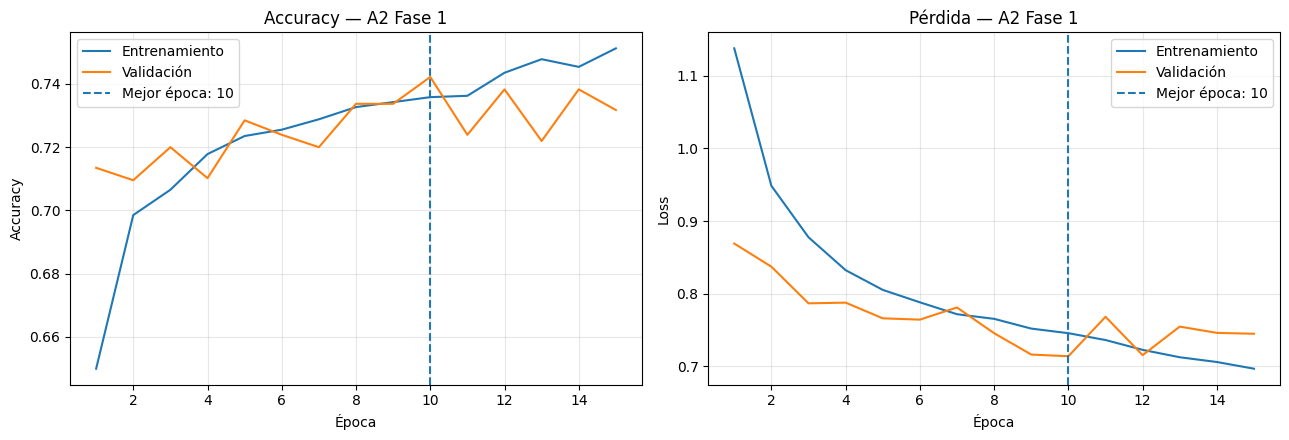


Historial guardado: /kaggle/working/metricas/historial_modelo_a2_fase1.csv
Gráfica guardada: /kaggle/working/graficas/entrenamiento_modelo_a2_fase1.png


In [33]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Guardar historial de entrenamiento
historial_df_a2_fase1 = pd.DataFrame(
    historial_a2_fase1.history
)

os.makedirs("/kaggle/working/metricas", exist_ok=True)
os.makedirs("/kaggle/working/graficas", exist_ok=True)

ruta_historial = (
    "/kaggle/working/metricas/"
    "historial_modelo_a2_fase1.csv"
)

historial_df_a2_fase1.to_csv(
    ruta_historial,
    index=False
)

# Identificar la mejor época según val_loss
mejor_epoca = (
    historial_df_a2_fase1["val_loss"].idxmin() + 1
)

print("Mejor época:", mejor_epoca)
print(
    "Mejor val_loss:",
    round(historial_df_a2_fase1["val_loss"].min(), 4)
)

print(
    "Accuracy en la mejor época:",
    round(
        historial_df_a2_fase1.loc[
            mejor_epoca - 1, "val_accuracy"
        ],
        4
    )
)

# Graficar curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

epocas = range(1, len(historial_df_a2_fase1) + 1)

axes[0].plot(
    epocas,
    historial_df_a2_fase1["accuracy"],
    label="Entrenamiento"
)
axes[0].plot(
    epocas,
    historial_df_a2_fase1["val_accuracy"],
    label="Validación"
)
axes[0].axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)
axes[0].set_title("Accuracy — A2 Fase 1")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epocas,
    historial_df_a2_fase1["loss"],
    label="Entrenamiento"
)
axes[1].plot(
    epocas,
    historial_df_a2_fase1["val_loss"],
    label="Validación"
)
axes[1].axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)
axes[1].set_title("Pérdida — A2 Fase 1")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

ruta_grafica = (
    "/kaggle/working/graficas/"
    "entrenamiento_modelo_a2_fase1.png"
)

plt.savefig(ruta_grafica, dpi=300, bbox_inches="tight")
plt.show()

print("\nHistorial guardado:", ruta_historial)
print("Gráfica guardada:", ruta_grafica)


In [34]:

import tensorflow as tf

# MODELO A2 - FASE 2
# Ajuste fino de las últimas 30 capas de EfficientNetB0

# Habilitar la posibilidad de entrenar la base
base_model_a2.trainable = True

# Congelar todas las capas excepto las últimas 30
for capa in base_model_a2.layers[:-30]:
    capa.trainable = False

# En las últimas 30 capas, mantener congeladas
# las capas BatchNormalization
for capa in base_model_a2.layers[-30:]:
    if isinstance(capa, tf.keras.layers.BatchNormalization):
        capa.trainable = False
    else:
        capa.trainable = True

# Recompilar después de modificar trainable
modelo_a2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Verificar configuración
capas_entrenables = sum(
    int(capa.trainable)
    for capa in base_model_a2.layers
)

capas_congeladas = sum(
    int(not capa.trainable)
    for capa in base_model_a2.layers
)

print("MODELO A2 - FASE 2")
print("Capas totales de EfficientNetB0:",
      len(base_model_a2.layers))
print("Capas entrenables de la base:",
      capas_entrenables)
print("Capas congeladas de la base:",
      capas_congeladas)

print("\nParámetros entrenables:",
      sum(
          tf.keras.backend.count_params(p)
          for p in modelo_a2.trainable_weights
      ))

print("Parámetros no entrenables:",
      sum(
          tf.keras.backend.count_params(p)
          for p in modelo_a2.non_trainable_weights
      ))

print("\nLearning rate:", 1e-5)


MODELO A2 - FASE 2
Capas totales de EfficientNetB0: 238
Capas entrenables de la base: 23
Capas congeladas de la base: 215

Parámetros entrenables: 1492327
Parámetros no entrenables: 2566211.0

Learning rate: 1e-05


In [35]:

import os
import tensorflow as tf

# MODELO A2 - FASE 2
# Configurar callbacks independientes

ruta_checkpoint_a2_fase2 = (
    "/kaggle/working/modelos/a2/"
    "modelo_a2_fase2_mejor.keras"
)

os.makedirs(
    "/kaggle/working/modelos/a2",
    exist_ok=True
)

checkpoint_a2_fase2 = tf.keras.callbacks.ModelCheckpoint(
    filepath=ruta_checkpoint_a2_fase2,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

early_stopping_a2_fase2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_a2_fase2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks_a2_fase2 = [
    checkpoint_a2_fase2,
    early_stopping_a2_fase2,
    reduce_lr_a2_fase2
]

# Entrenamiento
EPOCAS_A2_FASE2 = 20

historial_a2_fase2 = modelo_a2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_A2_FASE2,
    class_weight=pesos_clase_a2,
    callbacks=callbacks_a2_fase2,
    verbose=1
)

print("\nEntrenamiento A2 - Fase 2 finalizado.")
print("Checkpoint:", ruta_checkpoint_a2_fase2)


Epoch 1/20


E0000 00:00:1794438868.480615      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_HAM10000_A2_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7461 - loss: 0.7149
Epoch 1: val_loss improved from None to 0.72987, saving model to /kaggle/working/modelos/a2/modelo_a2_fase2_mejor.keras

Epoch 1: finished saving model to /kaggle/working/modelos/a2/modelo_a2_fase2_mejor.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 34s 112ms/step - accuracy: 0.7518 - loss: 0.7134 - val_accuracy: 0.7356 - val_loss: 0.7299 - learning_rate: 1.0000e-05
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7547 - loss: 0.6817
Epoch 2: val_loss did not improve from 0.72987
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 99ms/step - accuracy: 0.7559 - loss: 0.6862 - val_accuracy: 0.7258 - val_loss: 0.7549 - learning_rate: 1.0000e-05
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7526 - loss: 0.6962
Epoch 3: val_loss did not improve from 0.72987

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
219/219 ━━━━━━━━━━━━━━━━━━━━ 22s 98ms/step - accuracy: 0.7548 - loss: 0.67

In [36]:

import os

archivos = [
    "/kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras",
    "/kaggle/working/modelos/a2/modelo_a2_fase2_mejor.keras",
    "/kaggle/working/metricas/historial_modelo_a2_fase2.csv"
]

for archivo in archivos:
    if os.path.exists(archivo):
        print("EXISTE:", archivo)
    else:
        print("NO ENCONTRADO:", archivo)

print("\nVariable historial_a2_fase2:",
      "Disponible" if "historial_a2_fase2" in globals()
      else "No disponible")


EXISTE: /kaggle/working/modelos/a2/modelo_a2_fase1_mejor.keras
EXISTE: /kaggle/working/modelos/a2/modelo_a2_fase2_mejor.keras
NO ENCONTRADO: /kaggle/working/metricas/historial_modelo_a2_fase2.csv

Variable historial_a2_fase2: Disponible
